# 35 — Extracción con modelos de Google: Gemini 3.8 Flash y Gemini 4 Argon frente a `qwen3:8b`

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [ADR 0026](../docs/decisions/0026-adr-extension-extractor-con-modelos-hosted.md) ·
[ADR 0011](../docs/decisions/0011-adr-alineacion-rol-e-intervalos-del-experimento-a.md) ·
[ADR 0012](../docs/decisions/0012-adr-umbral-tau-del-experimento-a.md) ·
[notebook 28](28-jss-experimento-a.ipynb) · [notebook 33](33-jss-extraccion-con-modelos-de-pago.ipynb) ·
[notebook 34](34-jss-linea-base-openkos-0-7-3.ipynb) ·
[protocolo de la extensión](../docs/protocols/extraccion-hosted.md)

**Alcance.** Registro de las corridas de **un laboratorio** de la extensión descriptiva del Experimento A
(ADR 0026): los dos modelos de Google (`google-small` y `google-large`) reemplazan al extractor de C2 con el
*backend* compatible con OpenAI de OpenKOS 0.7.3 y se comparan con la corrida formal `experimento-a-formal`
(`qwen3:8b`, OpenKOS 0.7.0) y con la línea base `experimento-a-base-0-7-3` (`qwen3:8b`, OpenKOS 0.7.3). El
notebook lee las corridas guardadas en `reports/experiment-a/` y los espacios de trabajo de OpenKOS; **no
llama a ningún modelo generativo**. Toda cifra sale de funciones de `src/afg/experiments/` con test
(`hosted_comparison.py` y `hosted_notebook.py`); el notebook solo las invoca y las muestra.

**Cómo se reutiliza.** La primera celda de código define `PROVIDER` y deriva de
`config/hosted_extraction.toml` los modelos del laboratorio. Los notebooks de OpenAI y de Anthropic son una
copia de este con **un solo cambio** (`PROVIDER`) y con la sección 10 reescrita. Este notebook calcula con
el paquete y **no lee** `reports/experiment-a/hosted-comparison/comparacion.json`, que se sobrescribe con
cada laboratorio.

**Estado.** Descriptivo (ADR 0026, decisión 9): las series de evaluación ya se usaron en la corrida formal, de
modo que ningún resultado de este notebook confirma una hipótesis de la tesis. **Requisito:** el cálculo de
similitudes necesita Ollama en marcha con el modelo de embeddings `bge-m3`.

> **Aviso de alcance (ADR 0005).** Las series son series de **evaluación**. El notebook muestra solo
> **identificadores de serie y de reunión, nombres de modelo y cifras agregadas**. No muestra ni cita frases de
> decisión ni contenido de transcripciones. No contiene ninguna cifra del Experimento B.

# 1. Pregunta y regla prerregistrada

**Pregunta.** La extracción de decisiones es el eslabón débil de C2: con `qwen3:8b` encuentra menos de un
tercio de las decisiones de la referencia. ¿Un modelo más capaz de este laboratorio extrae más decisiones,
sin perder precision?

**Qué se hace.** Se declara el laboratorio, se derivan sus modelos de la configuración y se muestra la regla
que el ADR 0026 fijó antes de ver datos.

In [1]:
import json
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from afg.cli import make_alignment_similarity
from afg.evaluation.reference import load_series_reference
from afg.experiments.hosted_comparison import build_comparison
from afg.experiments.hosted_extraction import hosted_run_name, load_hosted_config
from afg.experiments.hosted_notebook import (
    LABELS,
    bridge_state,
    format_es,
    format_interval,
    local_baseline_state,
    operation_table,
    quality_table,
    recall_forest_rows,
)
from afg.shared.config import load_corpus_config
from afg.shared.paths import EXPERIMENT_A_DIR, OPENKOS_WORKSPACES_DIR

# The only line that changes between provider notebooks: "openai", "anthropic" or "google".
PROVIDER = "google"

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

config = load_hosted_config()
spec = config.comparison
EVALUATION_SERIES = load_corpus_config()["oe1"]["evaluation_series"]
TAU_KEYS = [f"{t:.2f}" for t in (spec.tau, *spec.sensitivity_taus)]
PROVIDER_NAME = LABELS.get(PROVIDER, PROVIDER)
MODEL_LABELS = [label for label, model in config.models.items() if model.provider == PROVIDER]
if not MODEL_LABELS:
    raise ValueError(f"The configuration has no model of provider {PROVIDER!r}.")
BASELINES = [
    ("formal", "Línea base principal: corrida formal (qwen3:8b, OpenKOS 0.7.0)"),
    ("local", "Segunda línea base: qwen3:8b con OpenKOS 0.7.3"),
]

display(
    pd.DataFrame(
        [
            {
                "Etiqueta": label,
                "Laboratorio": PROVIDER_NAME,
                "Modelo": config.models[label].model,
                "Punto de acceso": config.models[label].base_url,
                "Corrida": hosted_run_name(label),
                "Piloto": hosted_run_name(label, pilot=True),
            }
            for label in MODEL_LABELS
        ]
    )
)

,Etiqueta,Laboratorio,Modelo,Punto de acceso,Corrida,Piloto
0,google-small,Google,gemini-3.8-flash,https://generativelanguage.googleapis.com/v1beta/openai,experimento-a-hosted-google-small,experimento-a-piloto-google-small
1,google-large,Google,gemini-4-argon,https://generativelanguage.googleapis.com/v1beta/openai,experimento-a-hosted-google-large,experimento-a-piloto-google-large


In [2]:
n_family = len(config.models)
resamples = format(spec.bootstrap_resamples, ",").replace(",", ".")
family_level = format_es(100 * (1 - spec.family_alpha / n_family), 2)
taus_extra = " y ".join(format_es(t) for t in spec.sensitivity_taus)
display(
    Markdown(
        "**Regla de mejora (ADR 0026, decisión 7).** Para cada modelo se calcula la diferencia "
        "(modelo menos línea base) con un bootstrap pareado por reunión "
        f"({resamples} remuestreos, semilla {spec.bootstrap_seed}) y un nivel Bonferroni por "
        f"los {n_family} modelos de pago de la extensión "
        f"(1 menos {format_es(spec.family_alpha)}/{n_family}, es decir {family_level} %), "
        f"aunque aquí solo se analicen los de {PROVIDER_NAME}. Un modelo **mejora** la "
        "extracción cuando se cumplen **las dos** condiciones: (1) el intervalo de la "
        "diferencia de **recall** queda entero sobre 0 y (2) el límite inferior de la "
        "diferencia de **precision** no baja de "
        f"{format_es(spec.precision_margin)}. Si el intervalo de recall contiene el 0 el "
        "veredicto es «sin diferencia demostrada», aunque la precision o el F1 suban; si "
        "queda entero bajo 0, «empeora».\n\n"
        f"**Criterio principal.** τ = {format_es(spec.tau)}; {taus_extra} son sensibilidades. "
        "Se informa contra las dos líneas base, con la misma regla.\n\n"
        f"**Ajustes de los modelos de pago.** `reasoning_effort = {config.reasoning_effort}`, "
        f"{config.runs_per_model} repeticiones por serie, sin `seed` ni `temperature` (los "
        "proveedores los rechazan o los ignoran), "
        f"OpenKOS {config.required_version}, *embeddings* "
        f"`{config.embedding_model}` en el Ollama local."
    )
)

**Regla de mejora (ADR 0026, decisión 7).** Para cada modelo se calcula la diferencia (modelo menos línea base) con un bootstrap pareado por reunión (10.000 remuestreos, semilla 42) y un nivel Bonferroni por los 6 modelos de pago de la extensión (1 menos 0,05/6, es decir 99,17 %), aunque aquí solo se analicen los de Google. Un modelo **mejora** la extracción cuando se cumplen **las dos** condiciones: (1) el intervalo de la diferencia de **recall** queda entero sobre 0 y (2) el límite inferior de la diferencia de **precision** no baja de -0,05. Si el intervalo de recall contiene el 0 el veredicto es «sin diferencia demostrada», aunque la precision o el F1 suban; si queda entero bajo 0, «empeora».

**Criterio principal.** τ = 0,70; 0,75 y 0,80 son sensibilidades. Se informa contra las dos líneas base, con la misma regla.

**Ajustes de los modelos de pago.** `reasoning_effort = low`, 3 repeticiones por serie, sin `seed` ni `temperature` (los proveedores los rechazan o los ignoran), OpenKOS 0.7.3, *embeddings* `bge-m3` en el Ollama local.

# 2. Identidad de las corridas

**Pregunta.** ¿Con qué código, versiones y ajustes se hizo cada corrida?

**Qué se hace.** Se lee el manifiesto que cada corrida escribió al terminar. Todos los campos salen del
manifiesto, no de la configuración actual.

In [3]:
def read_manifest(run_name):
    path = EXPERIMENT_A_DIR / run_name / "manifest.json"
    return json.loads(path.read_text(encoding="utf-8")) if path.is_file() else None


def duration_text(manifest):
    created = pd.Timestamp(manifest["created_at"])
    updated = pd.Timestamp(manifest["updated_at"])
    minutes = int((updated - created).total_seconds() // 60)
    return f"{minutes // 60} h {minutes % 60} min"


manifests = {label: read_manifest(hosted_run_name(label)) for label in MODEL_LABELS}
columns = {}
for label, manifest in manifests.items():
    if manifest is None:
        columns[label] = {"Estado": "sin corrida"}
        continue
    kos = manifest["openkos"]
    columns[label] = {
        "Corrida": manifest["run_name"],
        "Commit del código": manifest["git_commit"][:12],
        "Árbol con cambios (git_dirty)": str(manifest["git_dirty"]).lower(),
        "Modelo (id servido)": kos["generative_model"],
        "Punto de acceso (base_url)": kos["base_url"],
        "Backend": kos["backend"],
        "Versión de OpenKOS": ", ".join(kos["versions"]),
        "Ollama (embeddings)": manifest["ollama_version"],
        "Modelo de embeddings": kos["embedding_model"],
        "reasoning_effort": kos["reasoning_effort"],
        "Tope de tokens de generación": kos["max_generation_tokens"],
        "seed / temperature": f"{kos['seed']} / {kos['temperature']}",
        "Series / repeticiones": f"{len(manifest['series_ids'])} / {manifest['runs']}",
        "Partición": manifest["partition"],
        "Estado del manifiesto": manifest["status"],
        "Duración (inicio a fin del manifiesto)": duration_text(manifest),
    }
display(pd.DataFrame(columns))

,google-small,google-large
Corrida,experimento-a-hosted-google-small,experimento-a-hosted-google-large
Commit del código,51b954fea923,51b954fea923
Árbol con cambios (git_dirty),false,false
Modelo (id servido),gemini-3.8-flash,gemini-4-argon
Punto de acceso (base_url),https://generativelanguage.googleapis.com/v1beta/openai,https://generativelanguage.googleapis.com/v1beta/openai
Backend,openai-compatible,openai-compatible
Versión de OpenKOS,0.7.3,0.7.3
Ollama (embeddings),0.40.16,0.40.16
Modelo de embeddings,bge-m3,bge-m3
reasoning_effort,low,low


In [4]:
commits = {m["git_commit"] for m in manifests.values() if m}
dirty = {m["git_dirty"] for m in manifests.values() if m}
display(
    Markdown(
        f"**Lectura.** Las corridas de {PROVIDER_NAME} se hicieron con "
        f"{'un mismo commit' if len(commits) == 1 else 'commits distintos'} "
        f"(`{', '.join(sorted(c[:12] for c in commits))}`) y `git_dirty = "
        f"{', '.join(str(d).lower() for d in sorted(dirty))}`. El modelo servido es el que pide la "
        f"configuración; si un identificador cambia de significado sin aviso, esta tabla es la "
        f"evidencia de qué se pidió (ADR 0026, decisión 3)."
    )
)

**Lectura.** Las corridas de Google se hicieron con un mismo commit (`51b954fea923`) y `git_dirty = false`. El modelo servido es el que pide la configuración; si un identificador cambia de significado sin aviso, esta tabla es la evidencia de qué se pidió (ADR 0026, decisión 3).

# 3. Pilotos

**Pregunta.** ¿Los pilotos (una serie, ES2002, una repetición) salieron bien antes de lanzar la corrida completa?

**Qué se hace.** Se leen los manifiestos de los pilotos y se calculan su costo y su tiempo con las mismas
funciones de la comparación. De un piloto no se informa calidad: es una sola repetición de una serie y solo
sirve para comprobar que la corrida funciona y para estimar el costo.

In [5]:
similarity = make_alignment_similarity()


def reference_of(series_id):
    return load_series_reference(series_id, language="en").decisions


bridge_ready = bridge_state(config, runs_root=EXPERIMENT_A_DIR)["state"] == "lista"
local_info = local_baseline_state(
    config, runs_root=EXPERIMENT_A_DIR, evaluation_series=EVALUATION_SERIES
)
pilot_payload = build_comparison(
    config=config,
    labels=MODEL_LABELS,
    include_bridge=False,
    pilot=True,
    runs_root=EXPERIMENT_A_DIR,
    workspaces_root=OPENKOS_WORKSPACES_DIR,
    reference_of=reference_of,
    similarity=similarity,
    baseline="formal",
)
pilot_rows = []
for item in pilot_payload["candidates"]:
    manifest = read_manifest(item["run_name"])
    if item["status"] != "ok" or manifest is None:
        pilot_rows.append({"Modelo": item["label"], "Estado": "sin piloto"})
        continue
    pairs = manifest["pairs"]
    ok_pairs = sum(1 for p in pairs.values() if p["status"] == "ok")
    operation = item["vs_formal"]["operation"]
    cost = operation["cost"]
    pilot_rows.append(
        {
            "Modelo": item["label"],
            "Commit": manifest["git_commit"][:12],
            "git_dirty": str(manifest["git_dirty"]).lower(),
            "Pares ok": f"{ok_pairs} de {len(pairs)}",
            "Reuniones con extracción": (
                f"{operation['completeness']['candidate']['complete']} de "
                f"{operation['completeness']['candidate']['expected']}"
            ),
            "Mediana por reunión (s)": format_es(operation["time"]["candidate_median_s"], 1),
            "Duración": duration_text(manifest),
            "Costo (USD)": ("≥ " if cost["lower_bound"] else "") + format_es(cost["total_usd"], 3),
        }
    )
display(pd.DataFrame(pilot_rows))
pilot_total = sum(
    item["vs_formal"]["operation"]["cost"]["total_usd"]
    for item in pilot_payload["candidates"]
    if item["status"] == "ok"
)
display(
    Markdown(
        f"**Lectura.** Los pilotos de {PROVIDER_NAME} costaron en total USD "
        f"{format_es(pilot_total, 3)} y sirvieron para decidir el lanzamiento de la corrida "
        f"completa. Sus cifras de calidad no se muestran ni entran en ningún veredicto."
    )
)

,Modelo,Commit,git_dirty,Pares ok,Reuniones con extracción,Mediana por reunión (s),Duración,Costo (USD)
0,google-small,51b954fea923,false,1 de 1,4 de 4,"81,6",0 h 4 min,"0,236"
1,google-large,51b954fea923,false,1 de 1,4 de 4,"252,0",0 h 14 min,"0,813"


**Lectura.** Los pilotos de Google costaron en total USD 1,049 y sirvieron para decidir el lanzamiento de la corrida completa. Sus cifras de calidad no se muestran ni entran en ningún veredicto.

# 4. Completitud y estado de la extracción

**Pregunta.** ¿Terminaron todas las extracciones y ninguna reunión quedó sin objetos extraídos?

**Qué se hace.** Se calcula la comparación completa de los modelos del laboratorio con **las dos líneas base**
(`build_comparison(..., baseline="both")`) y se cuentan los pares serie × repetición, las extracciones por
reunión completas y las reuniones con `extraction_status` (la marca que OpenKOS 0.7.3 deja cuando un `ingest`
no produjo ningún objeto; un `ingest` fallido termina con código 0, de modo que el código de salida no basta).

In [6]:
payload = build_comparison(
    config=config,
    labels=MODEL_LABELS,
    include_bridge=False,
    pilot=False,
    runs_root=EXPERIMENT_A_DIR,
    workspaces_root=OPENKOS_WORKSPACES_DIR,
    reference_of=reference_of,
    similarity=similarity,
    baseline="both",
)
rows = []
for item in payload["candidates"]:
    if item["status"] != "ok":
        rows.append({"Modelo": item["label"], "Estado": item["status"]})
        continue
    block = item["vs_formal"]
    manifest = manifests[item["label"]]
    pairs = manifest["pairs"]
    ok_pairs = sum(1 for p in pairs.values() if p["status"] == "ok")
    expected_pairs = block["n_series"] * config.runs_per_model
    done = block["operation"]["completeness"]["candidate"]
    statuses = block["operation"]["extraction_status"]["candidate"]
    rows.append(
        {
            "Modelo": item["label"],
            "Pares serie por repetición": f"{ok_pairs} de {expected_pairs}",
            "Series": block["n_series"],
            "Reuniones": block["n_meetings"],
            "Extracciones completas": f"{done['complete']} de {done['expected']}",
            "Con extraction_status": sum(statuses.values()),
            "Detalle de extraction_status": (
                "; ".join(f"{n} {name}" for name, n in statuses.items() if n) or "ninguno"
            ),
        }
    )
display(pd.DataFrame(rows))

,Modelo,Pares serie por repetición,Series,Reuniones,Extracciones completas,Con extraction_status,Detalle de extraction_status
0,google-small,33 de 33,11,44,132 de 132,0,ninguno
1,google-large,33 de 33,11,44,132 de 132,0,ninguno


In [7]:
ok_items = [item for item in payload["candidates"] if item["status"] == "ok"]
total_pairs = sum(
    1
    for item in ok_items
    for p in manifests[item["label"]]["pairs"].values()
    if p["status"] == "ok"
)
complete = sum(
    item["vs_formal"]["operation"]["completeness"]["candidate"]["complete"] for item in ok_items
)
expected = sum(
    item["vs_formal"]["operation"]["completeness"]["candidate"]["expected"] for item in ok_items
)
flagged = sum(
    sum(item["vs_formal"]["operation"]["extraction_status"]["candidate"].values())
    for item in ok_items
)
reading = (
    f"**Lectura.** Los {len(ok_items)} modelos de {PROVIDER_NAME} terminaron {total_pairs} "
    f"pares serie por repetición, con {complete} de {expected} extracciones por reunión "
    f"completas y {flagged} reuniones con `extraction_status`."
)
if flagged:
    reading += " Esas reuniones aportan cero decisiones a precision y recall."
else:
    reading += " Ninguna reunión se tuvo que contar como extracción vacía."
display(Markdown(reading))

**Lectura.** Los 2 modelos de Google terminaron 66 pares serie por repetición, con 264 de 264 extracciones por reunión completas y 0 reuniones con `extraction_status`. Ninguna reunión se tuvo que contar como extracción vacía.

# 5. Calidad de la extracción

**Pregunta.** ¿Cada modelo extrae más decisiones de la referencia que `qwen3:8b`, sin perder precision?

**Qué se muestra.** Precision, recall y F1 con τ = 0,70 (criterio principal) de cada modelo, la diferencia
frente a cada línea base (modelo menos línea base) con su intervalo bootstrap pareado por reunión y de nivel
Bonferroni, y el veredicto de la regla de la sección 1. Una diferencia positiva en recall significa que el
modelo encuentra más decisiones de la referencia; un intervalo que cruza el 0 no permite afirmar una
diferencia.

In [8]:
baseline_cells = {}
for baseline_key, baseline_title in BASELINES:
    display(Markdown(f"### {baseline_title}"))
    display(quality_table(payload, TAU_KEYS[0], baseline=baseline_key))
    for item in ok_items:
        block = item[f"vs_{baseline_key}"]
        if block["status"] == "ok":
            baseline_cells[baseline_key] = block["taus"][TAU_KEYS[0]]["baseline"]
level = format_es(100 * ok_items[0]["vs_formal"]["interval_level"], 2)
display(
    Markdown(
        f"Intervalos bootstrap pareados por reunión, {resamples} remuestreos, semilla "
        f"{spec.bootstrap_seed}, nivel {level} % (Bonferroni por {n_family} modelos). "
        f"Referencia de la línea base principal con τ = {format_es(spec.tau)}: precision "
        f"{format_es(baseline_cells['formal']['precision'], 3)}, recall "
        f"{format_es(baseline_cells['formal']['recall'], 3)}, F1 "
        f"{format_es(baseline_cells['formal']['f1'], 3)}."
    )
)

### Línea base principal: corrida formal (qwen3:8b, OpenKOS 0.7.0)

,Modelo,Series,Reuniones,Precision,Recall,F1,Δ Precision,Δ Recall,Δ F1,Veredicto,"Recall sube, precision cae"
0,google-small,11,44,"0,44","0,38","0,40","+0,29 [+0,21; +0,38]","+0,07 [-0,04; +0,19]","+0,20 [+0,13; +0,29]",sin diferencia demostrada,no
1,google-large,11,44,"0,30","0,71","0,42","+0,15 [+0,10; +0,20]","+0,40 [+0,28; +0,51]","+0,22 [+0,15; +0,29]",mejora,no


### Segunda línea base: qwen3:8b con OpenKOS 0.7.3

,Modelo,Series,Reuniones,Precision,Recall,F1,Δ Precision,Δ Recall,Δ F1,Veredicto,"Recall sube, precision cae"
0,google-small,11,44,"0,44","0,38","0,40","+0,29 [+0,21; +0,38]","+0,07 [-0,04; +0,19]","+0,21 [+0,13; +0,29]",sin diferencia demostrada,no
1,google-large,11,44,"0,30","0,71","0,42","+0,15 [+0,10; +0,20]","+0,40 [+0,29; +0,51]","+0,22 [+0,16; +0,29]",mejora,no


Intervalos bootstrap pareados por reunión, 10.000 remuestreos, semilla 42, nivel 99,17 % (Bonferroni por 6 modelos). Referencia de la línea base principal con τ = 0,70: precision 0,149, recall 0,308, F1 0,201.

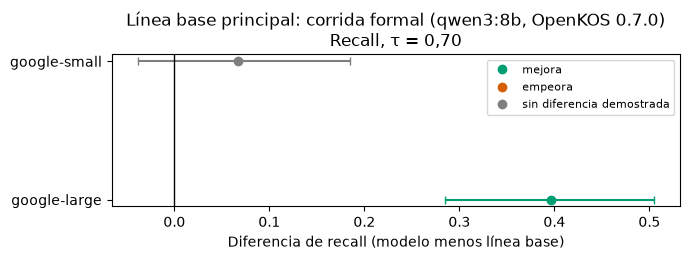

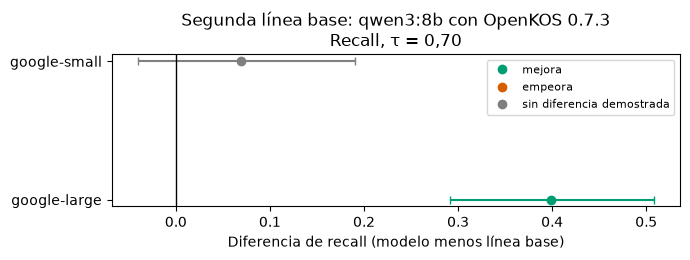

In [9]:
COLORS = {
    "mejora": "#009E73",
    "empeora": "#D55E00",
    "sin diferencia demostrada": "#7F7F7F",
}


def plot_recall_forest(rows, title):
    fig, ax = plt.subplots(figsize=(7, 0.55 * len(rows) + 1.6))
    for i, row in enumerate(rows):
        ax.errorbar(
            row["estimate"],
            i,
            xerr=[[row["estimate"] - row["low"]], [row["high"] - row["estimate"]]],
            fmt="o",
            color=COLORS.get(row["verdict"], "#7F7F7F"),
            capsize=3,
        )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(range(len(rows)), [row["label"] for row in rows])
    ax.invert_yaxis()
    ax.set_xlabel("Diferencia de recall (modelo menos línea base)")
    ax.set_title(title)
    handles = [
        plt.Line2D([], [], marker="o", linestyle="", color=c, label=v) for v, c in COLORS.items()
    ]
    ax.legend(handles=handles, loc="best", fontsize=8)
    fig.tight_layout()
    plt.show()


for baseline_key, baseline_title in BASELINES:
    plot_recall_forest(
        recall_forest_rows(payload, baseline=baseline_key),
        f"{baseline_title}\nRecall, τ = {format_es(spec.tau)}",
    )

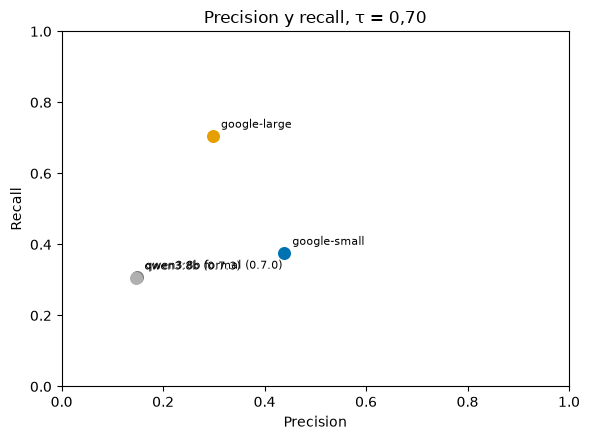

In [10]:
points = []
formal_ref = baseline_cells["formal"]
local_ref = baseline_cells["local"]
points.append(("qwen3:8b formal (0.7.0)", formal_ref["precision"], formal_ref["recall"], "#7F7F7F"))
points.append(("qwen3:8b (0.7.3)", local_ref["precision"], local_ref["recall"], "#B0B0B0"))
palette = ["#0072B2", "#E69F00", "#CC79A7", "#56B4E9"]
for i, item in enumerate(ok_items):
    cand = item["vs_formal"]["taus"][TAU_KEYS[0]]["candidate"]
    points.append((item["label"], cand["precision"], cand["recall"], palette[i % len(palette)]))
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, p, r, color in points:
    ax.scatter(p, r, s=70, color=color, label=name)
    ax.annotate(name, (p, r), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Precision")
ax.set_ylabel("Recall")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f"Precision y recall, τ = {format_es(spec.tau)}")
fig.tight_layout()
plt.show()

In [11]:
lines = []
for item in ok_items:
    parts = []
    for baseline_key, _ in BASELINES:
        entry = item[f"vs_{baseline_key}"]["taus"][TAU_KEYS[0]]
        diff = entry["diff"]
        shown = []
        for name, title in (("precision", "precision"), ("recall", "recall"), ("f1", "F1")):
            low, high = diff[name]["interval"]
            where = "cruza el 0" if low <= 0 <= high else ("sobre 0" if low > 0 else "bajo 0")
            figure = format_interval(diff[name]["estimate"], diff[name]["interval"], 3, signed=True)
            shown.append(f"{title} {figure} ({where})")
        parts.append(
            f"Contra {'la corrida formal' if baseline_key == 'formal' else 'qwen3:8b en 0.7.3'}: "
            + "; ".join(shown)
            + f". Veredicto **{entry['verdict']}**"
        )
    lines.append(f"- **{item['label']}** ({item['model']}). " + ". ".join(parts) + ".")
display(Markdown("**Lectura.** Con τ = " + format_es(spec.tau) + ":\n" + "\n".join(lines)))

**Lectura.** Con τ = 0,70:
- **google-small** (gemini-3.8-flash). Contra la corrida formal: precision +0,290 [+0,206; +0,381] (sobre 0); recall +0,067 [-0,039; +0,185] (cruza el 0); F1 +0,204 [+0,128; +0,288] (sobre 0). Veredicto **sin diferencia demostrada**. Contra qwen3:8b en 0.7.3: precision +0,292 [+0,208; +0,384] (sobre 0); recall +0,070 [-0,041; +0,191] (cruza el 0); F1 +0,206 [+0,128; +0,289] (sobre 0). Veredicto **sin diferencia demostrada**.
- **google-large** (gemini-4-argon). Contra la corrida formal: precision +0,149 [+0,100; +0,205] (sobre 0); recall +0,397 [+0,285; +0,505] (sobre 0); F1 +0,218 [+0,151; +0,289] (sobre 0). Veredicto **mejora**. Contra qwen3:8b en 0.7.3: precision +0,151 [+0,104; +0,203] (sobre 0); recall +0,399 [+0,292; +0,508] (sobre 0); F1 +0,220 [+0,156; +0,289] (sobre 0). Veredicto **mejora**.

# 6. Sensibilidad al umbral τ

La regla del ADR 0012 fija τ = 0,70 como criterio principal; 0,75 y 0,80 son sensibilidades. Se muestran los
tres para no ocultar que, con un umbral más exigente, el veredicto puede cambiar. La regla y el nivel
Bonferroni son los mismos en los tres.

In [12]:
rows = []
for item in ok_items:
    for baseline_key, _ in BASELINES:
        for key in TAU_KEYS:
            entry = item[f"vs_{baseline_key}"]["taus"][key]
            row = {
                "Modelo": item["label"],
                "Línea base": "formal" if baseline_key == "formal" else "0.7.3",
                "τ": format_es(entry["tau"]),
            }
            for name, title in (
                ("precision", "Δ precision"),
                ("recall", "Δ recall"),
                ("f1", "Δ F1"),
            ):
                diff = entry["diff"][name]
                row[title] = format_interval(diff["estimate"], diff["interval"], 3, signed=True)
            row["Veredicto"] = entry["verdict"]
            rows.append(row)
display(pd.DataFrame(rows))
verdicts = {}
for item in ok_items:
    for baseline_key, _ in BASELINES:
        verdicts[(item["label"], baseline_key)] = [
            item[f"vs_{baseline_key}"]["taus"][key]["verdict"] for key in TAU_KEYS
        ]
text = []
for item in ok_items:
    same = all(len(set(verdicts[(item["label"], b)])) == 1 for b, _ in BASELINES)
    if same:
        text.append(
            f"**{item['label']}**: el veredicto es el mismo en los tres umbrales y en las "
            f"dos líneas base («{verdicts[(item['label'], 'formal')][0]}»)."
        )
    else:
        detail = "; ".join(
            f"contra {'formal' if b == 'formal' else '0.7.3'}: "
            + ", ".join(
                f"τ {format_es(float(k))} «{v}»"
                for k, v in zip(TAU_KEYS, verdicts[(item["label"], b)], strict=True)
            )
            for b, _ in BASELINES
        )
        text.append(f"**{item['label']}**: el veredicto cambia con el umbral ({detail}).")
display(Markdown("**Lectura.** " + " ".join(text)))

,Modelo,Línea base,τ,Δ precision,Δ recall,Δ F1,Veredicto
0,google-small,formal,"0,70","+0,290 [+0,206; +0,381]","+0,067 [-0,039; +0,185]","+0,204 [+0,128; +0,288]",sin diferencia demostrada
1,google-small,formal,"0,75","+0,228 [+0,152; +0,315]","+0,074 [-0,005; +0,167]","+0,168 [+0,100; +0,242]",sin diferencia demostrada
2,google-small,formal,"0,80","+0,174 [+0,104; +0,246]","+0,088 [+0,014; +0,172]","+0,139 [+0,071; +0,211]",mejora
3,google-small,0.7.3,"0,70","+0,292 [+0,208; +0,384]","+0,070 [-0,041; +0,191]","+0,206 [+0,128; +0,289]",sin diferencia demostrada
4,google-small,0.7.3,"0,75","+0,236 [+0,160; +0,324]","+0,090 [+0,012; +0,180]","+0,179 [+0,109; +0,252]",mejora
5,google-small,0.7.3,"0,80","+0,180 [+0,109; +0,254]","+0,100 [+0,028; +0,182]","+0,147 [+0,079; +0,219]",mejora
6,google-large,formal,"0,70","+0,149 [+0,100; +0,205]","+0,397 [+0,285; +0,505]","+0,218 [+0,151; +0,289]",mejora
7,google-large,formal,"0,75","+0,123 [+0,075; +0,180]","+0,321 [+0,218; +0,434]","+0,179 [+0,113; +0,253]",mejora
8,google-large,formal,"0,80","+0,092 [+0,051; +0,139]","+0,234 [+0,142; +0,335]","+0,133 [+0,076; +0,194]",mejora
9,google-large,0.7.3,"0,70","+0,151 [+0,104; +0,203]","+0,399 [+0,292; +0,508]","+0,220 [+0,156; +0,289]",mejora


**Lectura.** **google-small**: el veredicto cambia con el umbral (contra formal: τ 0,70 «sin diferencia demostrada», τ 0,75 «sin diferencia demostrada», τ 0,80 «mejora»; contra 0.7.3: τ 0,70 «sin diferencia demostrada», τ 0,75 «mejora», τ 0,80 «mejora»). **google-large**: el veredicto es el mismo en los tres umbrales y en las dos líneas base («mejora»).

# 7. Decisiones por reunión y tiempo

**Pregunta.** ¿Cuántas decisiones extrae cada modelo por reunión, comparado con la referencia, y cuánto tarda?

**Qué se hace.** Se compara la media de decisiones extraídas por reunión con la de las dos líneas base y con el
promedio de decisiones de la referencia (conteo de decisiones de las series de evaluación dividido por las
reuniones). Extraer muchas más decisiones que la referencia suele bajar la precision; extraer pocas la sube,
pero limita el recall. El tiempo es la mediana del `ingest` por reunión, con la razón modelo ÷ línea base y su
intervalo bootstrap (sobre el logaritmo de la razón). Las líneas base corren en un equipo local y los modelos
en la infraestructura del proveedor: la razón describe la experiencia de uso, no la eficiencia del modelo.

In [13]:
n_reference = sum(len(reference_of(series)) for series in EVALUATION_SERIES)
n_meetings = ok_items[0]["vs_formal"]["n_meetings"]
rows = []
for item in ok_items:
    formal_op = item["vs_formal"]["operation"]
    local_op = item["vs_local"]["operation"]
    rows.append(
        {
            "Modelo": item["label"],
            "Decisiones por reunión (media)": format_es(
                formal_op["decisions_per_meeting"]["candidate"]["mean"], 1
            ),
            "qwen3:8b formal": format_es(formal_op["decisions_per_meeting"]["baseline"]["mean"], 1),
            "qwen3:8b 0.7.3": format_es(local_op["decisions_per_meeting"]["baseline"]["mean"], 1),
            "Referencia": format_es(n_reference / n_meetings, 1),
        }
    )
display(pd.DataFrame(rows))
for baseline_key, baseline_title in BASELINES:
    display(Markdown(f"### Tiempo: {baseline_title}"))
    table = operation_table(payload, baseline=baseline_key)
    display(
        table[
            [
                "Modelo",
                "Mediana por reunión (s)",
                "Línea base (s)",
                "Razón de tiempos",
                "Tiempo",
            ]
        ]
    )

,Modelo,Decisiones por reunión (media),qwen3:8b formal,qwen3:8b 0.7.3,Referencia
0,google-small,"5,4","13,1","13,2","6,3"
1,google-large,"15,0","13,1","13,2","6,3"


### Tiempo: Línea base principal: corrida formal (qwen3:8b, OpenKOS 0.7.0)

,Modelo,Mediana por reunión (s),Línea base (s),Razón de tiempos,Tiempo
0,google-small,67,307,"0,22 [0,19; 0,26]",más rápido
1,google-large,195,307,"0,66 [0,56; 0,78]",más rápido


### Tiempo: Segunda línea base: qwen3:8b con OpenKOS 0.7.3

,Modelo,Mediana por reunión (s),Línea base (s),Razón de tiempos,Tiempo
0,google-small,67,328,"0,20 [0,18; 0,23]",más rápido
1,google-large,195,328,"0,60 [0,52; 0,70]",más rápido


# 8. Tokens y costo

**Pregunta.** ¿Cuánto costó cada corrida y cuánto es exacto?

**Qué se hace.** El costo se calcula con los tokens que OpenKOS 0.7.3 informa por cada `ingest` y los precios
públicos de `config/hosted_extraction.toml`: tokens de entrada × precio de entrada + (tokens totales − tokens
de entrada) × precio de salida, por millón de tokens, de modo que el razonamiento oculto se cobra como salida.
Es **exacto** cuando todas las llamadas informaron sus tokens; si alguna no lo hizo, es una **cota inferior**
(«≥»). Los reintentos que hace OpenKOS por su cuenta se cobran y cuentan. Si falta el precio, el costo es
«pendiente» y nunca cero. Cada precio lleva su fecha y su página de origen, y las notas de la configuración
registran las promociones con fecha de término.

In [14]:
def price_notes(label):
    # Comment lines that follow the [prices.<label>] header in the configuration file.
    path = EXPERIMENT_A_DIR.parents[1] / "config" / "hosted_extraction.toml"
    text = path.read_text(encoding="utf-8")
    match = re.search(rf"^\[prices\.{re.escape(label)}\]\n((?:#.*\n)+)", text, re.MULTILINE)
    return (
        " ".join(line.lstrip("# ").strip() for line in match.group(1).splitlines())
        if match
        else "-"
    )


def thousands(value):
    return f"{value:,.0f}".replace(",", ".")


rows = []
for item in ok_items:
    operation = item["vs_formal"]["operation"]
    cost, tokens = operation["cost"], operation["tokens"]["candidate"]
    price = cost["prices"]
    rows.append(
        {
            "Modelo": item["label"],
            "Llamadas": f"{tokens['reported_calls']} de {tokens['calls']} con tokens",
            "Tokens de entrada": thousands(tokens["prompt"]),
            "Tokens de salida (total menos entrada)": thousands(tokens["total"] - tokens["prompt"]),
            "Mediana de tokens por reunión": thousands(tokens["median_total_per_meeting"]),
            "Costo (USD)": ("≥ " if cost["lower_bound"] else "") + format_es(cost["total_usd"], 3),
            "Exactitud": "cota inferior" if cost["lower_bound"] else "exacto",
            "Mediana por reunión (USD)": format_es(cost["median_per_meeting_usd"], 3),
            "Precio entrada / salida (USD por Mtok)": (
                f"{format_es(price['input_usd_per_mtok'])} / "
                f"{format_es(price['output_usd_per_mtok'])}"
            ),
            "Precio leído el": price["prices_date"],
        }
    )
display(pd.DataFrame(rows))
for item in ok_items:
    price = item["vs_formal"]["operation"]["cost"]["prices"]
    display(
        Markdown(
            f"- **{item['label']}**: {price_notes(item['label'])} Fuente: {price['pricing_url']}. "
            f"Control del panel del proveedor: "
            f"{item['vs_formal']['operation']['dashboard_usd'] or 'no registrado'}."
        )
    )
run_total = sum(item["vs_formal"]["operation"]["cost"]["total_usd"] for item in ok_items)
display(
    Markdown(
        f"**Lectura.** Las corridas completas de {PROVIDER_NAME} costaron USD "
        f"{format_es(run_total, 3)}; con los pilotos, USD {format_es(run_total + pilot_total, 3)}. "
        "Los precios de una promoción con fecha de término se aplican a la fecha de la "
        "corrida: una corrida repetida después de esa fecha costaría más."
    )
)

,Modelo,Llamadas,Tokens de entrada,Tokens de salida (total menos entrada),Mediana de tokens por reunión,Costo (USD),Exactitud,Mediana por reunión (USD),Precio entrada / salida (USD por Mtok),Precio leído el
0,google-small,2218 de 2218 con tokens,6.238.266,426.535,49.759,"6,278",exacto,"0,047","0,75 / 3,75",2026-11-26
1,google-large,2220 de 2220 con tokens,6.330.564,856.209,53.988,"21,223",exacto,"0,159","2,00 / 10,00",2026-11-26


- **google-small**: Introductory rate through 2026-12-31; 1.50 / 7.50 from 2027-01-01. Fuente: https://aistudio.google.com/docs/pricing. Control del panel del proveedor: no registrado.

- **google-large**: Introductory rate through 2026-11-30; 4.00 / 20.00 from 2026-12-01. The Google runs are planned to finish before that date; a run that bills on or after 2026-12-01 needs this table updated. Fuente: https://aistudio.google.com/docs/pricing. Control del panel del proveedor: no registrado.

**Lectura.** Las corridas completas de Google costaron USD 27,501; con los pilotos, USD 28,550. Los precios de una promoción con fecha de término se aplican a la fecha de la corrida: una corrida repetida después de esa fecha costaría más.

# 9. Lectura del equilibrio entre calidad y costo

**Pregunta.** Con todo lo anterior, ¿qué compra cada modelo de este laboratorio y a qué precio?

**Qué se hace.** Se resumen, por modelo, las cifras que deciden la lectura: veredicto de la regla, precision,
recall, decisiones por reunión, tiempo y costo.

In [15]:
rows = []
for item in ok_items:
    entry = item["vs_formal"]["taus"][TAU_KEYS[0]]
    local_entry = item["vs_local"]["taus"][TAU_KEYS[0]]
    operation = item["vs_formal"]["operation"]
    rows.append(
        {
            "Modelo": item["label"],
            "Veredicto (formal)": entry["verdict"],
            "Veredicto (0.7.3)": local_entry["verdict"],
            "Precision": format_es(entry["candidate"]["precision"], 3),
            "Recall": format_es(entry["candidate"]["recall"], 3),
            "F1": format_es(entry["candidate"]["f1"], 3),
            "Decisiones por reunión": format_es(
                operation["decisions_per_meeting"]["candidate"]["mean"], 1
            ),
            "Mediana por reunión (s)": format_es(operation["time"]["candidate_median_s"], 0),
            "Costo (USD)": ("≥ " if operation["cost"]["lower_bound"] else "")
            + format_es(operation["cost"]["total_usd"], 2),
        }
    )
display(pd.DataFrame(rows))

,Modelo,Veredicto (formal),Veredicto (0.7.3),Precision,Recall,F1,Decisiones por reunión,Mediana por reunión (s),Costo (USD)
0,google-small,sin diferencia demostrada,sin diferencia demostrada,"0,438","0,375","0,404","5,4",67,"6,28"
1,google-large,mejora,mejora,"0,298","0,705","0,419","15,0",195,"21,22"


**Interpretación para Google** *(texto escrito a mano para este laboratorio; en los notebooks de OpenAI y de
Anthropic se reescribe a la vista de su tabla).*

- **El modelo pequeño (`google-small`) es selectivo y barato.** Extrae pocas decisiones por reunión, y de lo
  que extrae una parte mucho mayor está en la referencia (precision muy por encima de la línea base), pero
  encuentra más o menos las mismas decisiones que `qwen3:8b`: el intervalo del recall incluye el 0. Por la
  regla prerregistrada, que exige una ganancia demostrada de recall, no es una mejora. Es la opción de menor
  costo y de menor tiempo por reunión.
- **El modelo grande (`google-large`) tiene recall alto.** Encuentra una parte mucho mayor de la referencia
  y su ganancia de recall es demostrada en los tres umbrales; paga con una precision más baja (extrae más
  decisiones de las que hay en la referencia) y con un costo y un tiempo bastante mayores. Cumple la regla de
  mejora.
- **Qué no se afirma.** Que un modelo sea «mejor» en general: la regla mide recall con un piso de precision, y
  la precision con τ = 0,70 depende de cuántas decisiones extra son válidas aunque no estén en la
  referencia, algo que esta medición no distingue.

# 10. Límites

- **Es una extensión descriptiva.** Las series de evaluación ya se usaron en la corrida formal y el equipo ya
  vio sus cifras. Ningún resultado de este notebook confirma una hipótesis de la tesis.
- **Solo la extracción de decisiones.** Este notebook mide si un modelo encuentra más decisiones de la
  referencia. Si las respuestas de C2 mejoran con ese extractor se mide aparte, con el Experimento B de C2
  (ADR 0026, tercera enmienda).
- **Los modelos de pago cambian sin aviso detrás del mismo identificador.** Cada cifra vale para el modelo
  tal como se sirvió en la fecha de su corrida (sección 2).
- **`reasoning_effort = low` en todos los modelos de la extensión.** El ajuste es el mismo para no tratar
  distinto a ningún laboratorio, pero no es el óptimo de ninguno.
- **Sin `seed` ni `temperature`.** Las tres repeticiones miden la variabilidad que eso introduce; los
  intervalos la incluyen porque cada reunión aporta el promedio de sus repeticiones.
- **Dos líneas base.** La corrida formal es la principal; la segunda (`qwen3:8b` con OpenKOS 0.7.3) se agregó
  tras ver el puente de la 0.7.2 y mide, además del cambio de OpenKOS, el de Ollama (cuarta enmienda).
- **El tiempo depende del equipo.** Las líneas base corren en un equipo local y los modelos en la
  infraestructura del proveedor, con carga y red distintas.
- **El costo es descriptivo.** Se calcula con los tokens informados y los precios de la fecha anotada; las
  promociones con fecha de término no valen después de ella (sección 8).
- **Dos modelos de un solo laboratorio.** No se generaliza a otros laboratorios ni a otros ajustes; el
  resultado de conjunto se escribe en el notebook general, cuando existan los seis modelos.
- **Datos a terceros.** Las transcripciones de AMI (CC BY 4.0, sin datos personales sensibles) se envían al
  proveedor de cada modelo (ADR 0026, consecuencias).